# Tasks 2.2 – 2.4 

In [1]:
from google.colab import drive
drive.mount('/content/drive')
import os, glob

hits = glob.glob('/content/drive/MyDrive/**/predicciones.json', recursive=True)
print(hits)
if hits:
    os.chdir(os.path.dirname(hits[0]))
    print("Trabajando en:", os.getcwd())
else:
    print("No hay predicciones.json en tu Drive. Corre primero el notebook 04.")

Mounted at /content/drive
['/content/drive/MyDrive/hdt7 ms/predicciones.json']
Trabajando en: /content/drive/MyDrive/hdt7 ms


In [2]:
# --- Parámetros del grupo ---
import math
g = 3                                   # <-- número de grupo (cambiar aquí)
mu = 0.25
lam = 3.0 + 0.2 * ((g - 1) % 5)
c = 17 + ((g - 1) % 3)
a = lam / mu
rho = a / c
k_off = math.ceil(c - a) + 3
Tb = 7
print(f"Grupo {g}: lambda={lam:.1f}/día, c={c}, a={a:.2f}, rho={rho:.4f}, k_off={k_off}, Tb={Tb} días")

import numpy as np

def erlang_b(c, a):
    """Recurrencia: B(0)=1;  B(k) = a B(k-1) / (k + a B(k-1))"""
    B = 1.0
    for k in range(1, c + 1):
        B = a * B / (k + a * B)
    return B

def erlang_c_direct(c, a):
    """C(c,a) = [a^c/c! /(1-rho)] / [sum_{k<c} a^k/k! + a^c/c! /(1-rho)]  (estable vía logs)"""
    from math import lgamma, log, exp
    rho = a / c
    terms = [exp(k*log(a) - lgamma(k+1)) for k in range(c)]
    top = exp(c*log(a) - lgamma(c+1)) / (1 - rho)
    return top / (sum(terms) + top)

def theory_wait(lam, mu, c):
    a = lam / mu; rho = a / c
    assert rho < 1
    B = erlang_b(c, a)
    C = B / (1 - rho * (1 - B))             # Erlang C a partir de Erlang B
    Lq = C * rho / (1 - rho)
    Wq = Lq / lam                            # = C/(c mu - lam)
    W = Wq + 1 / mu
    L = Lq + a
    return dict(a=a, rho=rho, C=C, Lq=Lq, Wq_h=Wq*24, W_h=W*24, Wq=Wq, W=W, L=L, util=rho, Pwait=C)

def theory_loss(lam, mu, c):
    a = lam / mu
    B = erlang_b(c, a)
    lam_eff = lam * (1 - B)
    L = lam_eff / mu                         # = a (1-B)
    return dict(B=B, lam_eff=lam_eff, L=L, util=L / c, W=1/mu, Pblock=B)


import heapq, itertools
from collections import deque
import numpy as np
from scipy import stats

def make_stay(dist, mean, cs, rng):
    """Estancia con media `mean` y coeficiente de variación `cs`."""
    if dist == 'det':
        return lambda: mean
    if dist == 'exp':
        return lambda: rng.exponential(mean)
    if dist == 'logn':
        s2 = np.log(1 + cs**2); m = np.log(mean) - s2 / 2; s = np.sqrt(s2)   # media y sd del log
        return lambda: rng.lognormal(m, s)
    raise ValueError(dist)

def simulate2(lam, c, T, warmup=0.0, seed=None, wait=True, stay_mean=4.0, dist='exp', cs=1.0,
              closure=None, sample_dt=None, inter_fn=None):
    """DES con lista de eventos. closure=(t0, Tb, k_off): en [t0, t0+Tb) la capacidad es c-k_off.
    Modelo del cierre: los pacientes en cama NO son expulsados; las camas cerradas dejan de
    ocupar cupo a medida que se liberan (no hay admisiones mientras ocupadas >= capacidad).
    Al reabrir, la fila entra de inmediato a las camas libres."""
    rng = np.random.default_rng(seed)
    ia = inter_fn or (lambda: rng.exponential(1.0 / lam))
    sv = make_stay(dist, stay_mean, cs, rng)
    ev, cnt = [], itertools.count()
    def push(t, k, d=None): heapq.heappush(ev, (t, next(cnt), k, d))
    push(ia(), 'A'); push(T, 'END')
    if warmup > 0: push(warmup, 'WARM')
    if closure:
        t0, Tb, koff = closure
        push(t0, 'CLOSE'); push(t0 + Tb, 'OPEN')
    cap, busy, q = c, 0, deque()
    meas, last = warmup <= 0, 0.0
    aL = aL2 = aLq = aB = 0.0
    n_arr = n_blk = n_delayed = 0
    waits, soj = [], []
    S_q, S_b, next_s = [], [], 0.0
    state_open = None

    def admit(t, a_t, counted):
        nonlocal busy
        busy += 1
        if counted: waits.append(t - a_t)          # espera medida desde la LLEGADA
        push(t + sv(), 'D', (a_t, counted))

    while ev:
        t, _, kind, data = heapq.heappop(ev)
        if sample_dt:
            while next_s <= min(t, T):
                S_q.append(len(q)); S_b.append(busy); next_s += sample_dt
        if kind == 'END':
            if meas:
                dt = T - last; n = busy + len(q)
                aL += n * dt; aL2 += n * n * dt; aLq += len(q) * dt; aB += busy * dt
            break
        if meas:
            dt = t - last; n = busy + len(q)
            aL += n * dt; aL2 += n * n * dt; aLq += len(q) * dt; aB += busy * dt
        last = t
        if kind == 'WARM':
            meas = True
        elif kind == 'CLOSE':
            cap = c - koff
        elif kind == 'OPEN':
            state_open = (busy, len(q))
            cap = c
            while q and busy < cap:
                a_t, cn = q.popleft(); admit(t, a_t, cn)
        elif kind == 'A':
            push(t + ia(), 'A')
            counted = meas; n_arr += counted
            if busy < cap:
                admit(t, t, counted)
            elif wait:
                n_delayed += counted; q.append((t, counted))
            else:
                n_blk += counted
        elif kind == 'D':
            a_t0, counted = data
            busy -= 1
            if counted: soj.append(t - a_t0)
            while q and busy < cap:
                a_t, cn = q.popleft(); admit(t, a_t, cn)

    span = T - warmup
    L = aL / span
    return dict(L=L, VarN=aL2 / span - L**2, Lq=aLq / span, util=aB / span / c,
                Pwait=(n_delayed / n_arr) if (wait and n_arr) else 0.0,
                Pblock=(n_blk / n_arr) if (n_arr and not wait) else 0.0,
                Wq=float(np.mean(waits)) if waits else np.nan,
                W=float(np.mean(soj)) if soj else np.nan,
                lam_eff=(n_arr - n_blk) / span, n_arr=n_arr, span=span,
                S_q=np.array(S_q), S_b=np.array(S_b), state_open=state_open)

def run_reps2(R, master_seed, **kw):
    seeds = np.random.SeedSequence(master_seed).spawn(R)
    return [simulate2(seed=s, **kw) for s in seeds]

def ci95(x):
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    m = x.mean(); h = stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))
    return m, h


Grupo 3: lambda=3.4/día, c=19, a=13.60, rho=0.7158, k_off=9, Tb=7 días


In [3]:
import json, pandas as pd, matplotlib.pyplot as plt
pred = json.load(open("predicciones.json"))
print("Predicciones congeladas el", pred["timestamp"])
tw = theory_wait(lam, mu, c); stay = 1 / mu

Predicciones congeladas el 2026-10-15T17:52:41


## Pruebas del simulador generalizado 
1. Cierre determinista de 2 camas calculado a mano (Lq=4.5/12, Wq=4.5/11, P(esperar)=5/11).
2. M/G/1 con CS=0,1,2: Pollaczek–Khinchine exacto, $W_q=\\frac{\\rho}{1-\\rho}\\frac{1+C_S^2}{2}\\frac1\\mu$ (c=1: Allen–Cunneen es exacta).

In [4]:
r = simulate2(0, 2, 12.0, inter_fn=lambda: 1.0, stay_mean=1.5, dist='det', closure=(5.5, 4.0, 1))
assert abs(r['Lq'] - 4.5/12) < 1e-12 and abs(r['Wq'] - 4.5/11) < 1e-12 and abs(r['Pwait'] - 5/11) < 1e-12
print("cierre a mano: OK  (Lq, Wq, P(esperar) exactos)")
for cs_, d in [(0, 'det'), (1, 'exp'), (2, 'logn')]:
    rr = run_reps2(30, 5, lam=0.5, c=1, T=40000.0, warmup=200.0, stay_mean=1.0, dist=d, cs=cs_)
    m, h = ci95([x['Wq'] for x in rr]); th = (0.5/0.5) * (1 + cs_**2) / 2
    print(f"M/G/1 CS={cs_}: sim Wq={m:.4f} ± {h:.4f}   P-K={th:.4f}   dentro={abs(m-th) <= h}")

cierre a mano: OK  (Lq, Wq, P(esperar) exactos)
M/G/1 CS=0: sim Wq=0.4994 ± 0.0041   P-K=0.5000   dentro=True
M/G/1 CS=1: sim Wq=0.9965 ± 0.0167   P-K=1.0000   dentro=True
M/G/1 CS=2: sim Wq=2.5486 ± 0.1297   P-K=2.5000   dentro=True


## Task 2.2 
Lognormal: $s^2=\\ln(1+C_S^2)$, $m=\\ln(1/\\mu)-s^2/2$. 40 réplicas, T=10 000 d, calentamiento 100 d.

In [5]:
s2 = np.log(1 + 2**2); m_ln = np.log(stay) - s2/2
x = np.random.default_rng(1).lognormal(m_ln, np.sqrt(s2), 2_000_000)
print(f"lognormal: s²={s2:.4f}, m={m_ln:.4f};  media muestral={x.mean():.3f} d (objetivo {stay}),  CV muestral={x.std()/x.mean():.2f} (objetivo 2)")
R2, T2, WU2 = 40, 10000.0, 100.0
cfg = {0: ('det', 'determinista'), 1: ('exp', 'exponencial'), 2: ('logn', 'lognormal')}
res22 = {cs_: run_reps2(R2, 100 + cs_, lam=lam, c=c, T=T2, warmup=WU2, stay_mean=stay, dist=d, cs=cs_) for cs_, (d, _) in cfg.items()}
rows = []
for cs_, (d, nm) in cfg.items():
    m, h = ci95([x['Wq']*24 for x in res22[cs_]])
    ac = pred['AC_Wq_h'][str(cs_)]
    rows.append(dict(CS=cs_, dist=nm, Wq_sim_h=m, IC_low=m-h, IC_high=m+h, AC_h=ac, err_AC=(ac-m)/m,
                     mi_pred_sim_h=pred['sim_Wq_pred_h'][str(cs_)], err_mi_pred=(pred['sim_Wq_pred_h'][str(cs_)]-m)/m,
                     err_AC_pred=pred['err_AC_pred'][str(cs_)]))
tab22 = pd.DataFrame(rows).set_index('CS'); tab22.round(4)

lognormal: s²=1.6094, m=0.5816;  media muestral=4.000 d (objetivo 4.0),  CV muestral=2.01 (objetivo 2)


,dist,Wq_sim_h,IC_low,IC_high,AC_h,err_AC,mi_pred_sim_h,err_mi_pred,err_AC_pred
CS,,,,,,,,,
0,determinista,1.2574,1.2219,1.2929,1.0698,-0.1492,1.3000,0.0339,-0.17
1,exponencial,2.1353,2.0147,2.2558,2.1396,0.0020,2.1396,0.0020,0.00
2,lognormal,3.2237,2.9554,3.4921,5.3490,0.6593,3.5000,0.0857,0.50


In [6]:
ev = []
for cs_, (d, nm) in cfg.items():
    rr = res22[cs_]
    Pw = ci95([x['Pwait'] for x in rr]); Lq = ci95([x['Lq'] for x in rr]); Wq = ci95([x['Wq']*24 for x in rr]); V = ci95([x['VarN'] for x in rr])
    ev.append(dict(CS=cs_, Pwait=Pw[0], Pwait_h=Pw[1], Lq=Lq[0], Lq_h=Lq[1], Wq_h_total=Wq[0], Wq_dado_esperar_h=Wq[0]/Pw[0],
                   residual_medio_d=stay*(1+cs_**2)/2, VarN=V[0], VarN_h=V[1]))
ev22 = pd.DataFrame(ev).set_index('CS'); print("Var(N) teórica si fuera M/G/∞ (Poisson) =", a); ev22.round(4)

Var(N) teórica si fuera M/G/∞ (Poisson) = 13.6


,Pwait,Pwait_h,Lq,Lq_h,Wq_h_total,Wq_dado_esperar_h,residual_medio_d,VarN,VarN_h
CS,,,,,,,,,
0,0.1075,0.0019,0.1780,0.0052,1.2574,11.6950,2.0,14.1753,0.1177
1,0.1205,0.0036,0.3026,0.0172,2.1353,17.7230,4.0,16.8904,0.3643
2,0.1247,0.0053,0.4575,0.0386,3.2237,25.8424,10.0,21.4165,1.1911


## Task 2.3 
$t_0=60$ d (después del calentamiento), **4000 réplicas** por caso (el enunciado pide ≥100; la curva promedio de una fila casi siempre vacía es ruidosa y el criterio 1.1·Lq es muy sensible al ruido), muestreo cada 0.1 d. Cierre en $[60,67)$ con capacidad $c-k_{off}=10$; reapertura en $t=67$. Se comparan estancia exponencial y determinista (misma media).

In [7]:
t0, R3, DT = 60.0, 4000, 0.1
Tend = t0 + Tb + 60.0
close = (t0, Tb, k_off)
res23 = {d: run_reps2(R3, 300 + i, lam=lam, c=c, T=Tend, warmup=0.0, stay_mean=stay, dist=d, cs=1.0, closure=close, sample_dt=DT)
         for i, d in enumerate(['exp', 'det'])}
n = min(len(x['S_q']) for r_ in res23.values() for x in r_)
tgrid = np.arange(n) * DT
Qmat = {d: np.array([x['S_q'][:n] for x in rr]) for d, rr in res23.items()}
Nmat = {d: np.array([x['S_q'][:n] + x['S_b'][:n] for x in rr]) for d, rr in res23.items()}
Qbar = {d: Qmat[d].mean(axis=0) for d in Qmat}; Nbar = {d: Nmat[d].mean(axis=0) for d in Nmat}
t_open = t0 + Tb
# Valor estacionario de Lq: exp = teoría M/M/c; det = simulación larga del Task 2.2 (40 réplicas, T=10000)
Lq_ss = {'exp': tw['Lq'], 'det': ev22.loc[0, 'Lq']}
pre = (tgrid >= 30) & (tgrid < t0)
print("Chequeo del estado estacionario antes del cierre (t∈[30,60)):",
      {d: round(Qbar[d][pre].mean(), 4) for d in Qbar}, "| valor usado:", {d: round(v, 4) for d, v in Lq_ss.items()})
post = tgrid > t_open
def first_below(Qm, thr):
    idx = np.where(post & (Qm < thr))[0]
    return tgrid[idx[0]] - t_open if len(idx) else np.nan
def last_above(Qm, thr):
    idx = np.where(post & (Qm >= thr))[0]
    return tgrid[idx[-1]] - t_open if len(idx) else 0.0
rec = {d: first_below(Qbar[d], 1.1 * Lq_ss[d]) for d in Qbar}            # definición del enunciado
rows = []
for mult in [3, 2, 1.5, 1.25, 1.1]:
    rows.append({"umbral": f"{mult}·Lq", **{f"{d} primer cruce [d]": first_below(Qbar[d], mult * Lq_ss[d]) for d in Qbar},
                 **{f"{d} último valor sobre el umbral [d]": last_above(Qbar[d], mult * Lq_ss[d]) for d in Qbar}})
rows.append({"umbral": "fila media < 1 paciente", **{f"{d} primer cruce [d]": first_below(Qbar[d], 1.0) for d in Qbar},
             **{f"{d} último valor sobre el umbral [d]": last_above(Qbar[d], 1.0) for d in Qbar}})
rec_table = pd.DataFrame(rows).set_index("umbral")
def boot(d, B=200, seed=0):
    rng = np.random.default_rng(seed); Q = Qmat[d]; out = []
    for _ in range(B):
        out.append(first_below(Q[rng.integers(0, len(Q), len(Q))].mean(axis=0), 1.1 * Lq_ss[d]))
    return np.nanpercentile(out, [2.5, 97.5])
ci_rec = {d: boot(d) for d in ['exp', 'det']}
print(f"Tiempo de recuperación (primer instante con fila media < 1.1·Lq, desde la reapertura): exp {rec['exp']:.1f} d (IC95% bootstrap {ci_rec['exp'][0]:.1f}–{ci_rec['exp'][1]:.1f}),  det {rec['det']:.1f} d (IC {ci_rec['det'][0]:.1f}–{ci_rec['det'][1]:.1f})")
print(f"Fórmula 2.1b: Td = {pred['Td_dias']:.2f} d | mi predicción de la simulación: {pred['Td_sim_pred_dias']} d")
rec_table.round(2)

Chequeo del estado estacionario antes del cierre (t∈[30,60)): {'exp': np.float64(0.3045), 'det': np.float64(0.1849)} | valor usado: {'exp': 0.3031, 'det': np.float64(0.178)}
Tiempo de recuperación (primer instante con fila media < 1.1·Lq, desde la reapertura): exp 31.1 d (IC95% bootstrap 26.1–35.8),  det 16.2 d (IC 16.0–20.3)
Fórmula 2.1b: Td = 4.67 d | mi predicción de la simulación: 6.5 d


,exp primer cruce [d],det primer cruce [d],exp último valor sobre el umbral [d],det último valor sobre el umbral [d]
umbral,,,,
3·Lq,10.2,8.0,10.1,12.0
2·Lq,15.0,8.0,14.9,16.0
1.5·Lq,19.7,12.1,19.6,20.0
1.25·Lq,27.5,16.1,27.4,20.0
1.1·Lq,31.1,16.2,59.0,36.6
fila media < 1 paciente,9.3,4.0,9.2,7.9


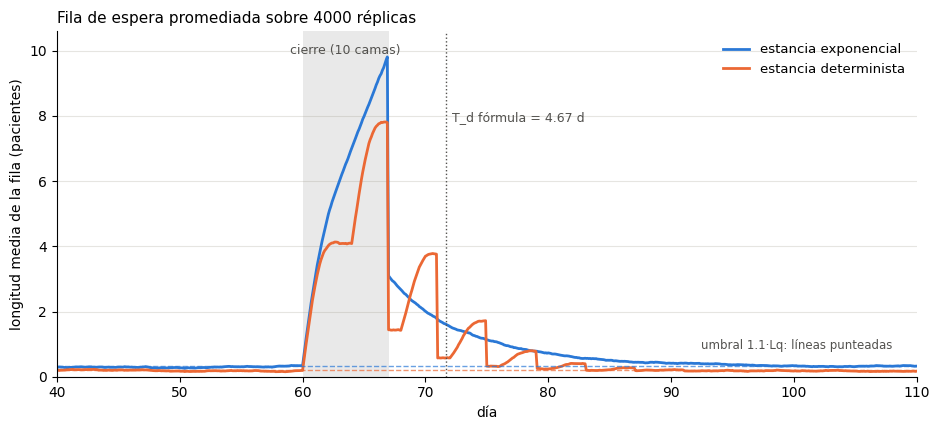

In [8]:
# --- Gráfico (paleta validada, slots 1 y 2) ---
C1, C2 = "#2a78d6", "#eb6834"
fig, ax = plt.subplots(figsize=(9.5, 4.4))
ax.axvspan(t0, t_open, color="#8a8a85", alpha=0.18, lw=0)
ax.plot(tgrid, Qbar['exp'], color=C1, lw=2, label="estancia exponencial"); ax.plot(tgrid, Qbar['det'], color=C2, lw=2, label="estancia determinista")
ax.axhline(1.1 * Lq_ss['exp'], color=C1, lw=1, ls="--", alpha=0.7); ax.axhline(1.1 * Lq_ss['det'], color=C2, lw=1, ls="--", alpha=0.7)
ax.axvline(t_open + pred['Td_dias'], color="#52514e", lw=1, ls=":")
ymax = max(Qbar['exp'].max(), Qbar['det'].max()); ax.set_ylim(0, ymax * 1.08)
ax.text(t0 + Tb/2, ymax * 1.04, "cierre (10 camas)", ha="center", va="top", color="#52514e", fontsize=9)
ax.text(t_open + pred['Td_dias'] + 0.5, ymax * 0.8, f"T_d fórmula = {pred['Td_dias']:.2f} d", color="#52514e", fontsize=9)
ax.text(108, 0.85, "umbral 1.1·Lq: líneas punteadas", color="#52514e", fontsize=8.5, ha="right")
ax.legend(loc="upper right", frameon=False, fontsize=9.5)
ax.set_xlim(40, 110); ax.set_xlabel("día"); ax.set_ylabel("longitud media de la fila (pacientes)")
ax.set_title("Fila de espera promediada sobre 4000 réplicas", loc="left", fontsize=11)
for s_ in ("top", "right"): ax.spines[s_].set_visible(False)
ax.grid(axis="y", color="#e6e5e1", lw=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig("cierre_fila.png", dpi=120); plt.savefig("cierre_fila.svg"); plt.show()

### Descomposición de la discrepancia con el modelo de acumulación
El modelo fluido supone (a) que la fila crece a $\\lambda-\\mu(c-k_{off})$ desde el primer instante, (b) que al reabrir baja a $\\mu c-\\lambda$ y (c) que «recuperarse» es vaciar la fila. Se reemplaza cada supuesto por lo medido (fila y camas ocupadas en el instante de reapertura).

In [9]:
rows = []
for d in ['exp', 'det']:
    rr = res23[d]; rate = mu * c - lam
    Qb = np.array([x['state_open'][1] for x in rr]); Bb = np.array([x['state_open'][0] for x in rr])
    free = c - Bb; Qafter = np.maximum(Qb - free, 0)
    rows.append(dict(estancia=d, Qb_fluido=pred['Qb'], Qb_sim=Qb.mean(), sd_Qb=Qb.std(), camas_libres_al_reabrir=free.mean(),
                     fila_tras_absorcion=Qafter.mean(), Td_fluido=pred['Td_dias'], Td_con_Qb_sim=Qb.mean()/rate,
                     Td_con_absorcion=Qafter.mean()/rate, T_fila_media_menor_1=first_below(Qbar[d], 1.0), T_recuperacion_1_1=rec[d]))
decomp = pd.DataFrame(rows).set_index('estancia'); decomp.round(3)

,Qb_fluido,Qb_sim,sd_Qb,camas_libres_al_reabrir,fila_tras_absorcion,Td_fluido,Td_con_Qb_sim,Td_con_absorcion,T_fila_media_menor_1,T_recuperacion_1_1
estancia,,,,,,,,,,
exp,6.3,9.894,6.544,9.122,3.099,4.667,7.329,2.296,9.3,31.1
det,6.3,7.788,4.854,9.078,1.439,4.667,5.769,1.066,4.0,16.2


In [10]:
Tfl, Texp, Tdet = pred['Td_dias'], rec['exp'], rec['det']
print(f"T_sim(exp) - T_fluido = {Texp - Tfl:+.1f} d   |   T_sim(det) - T_fluido = {Tdet - Tfl:+.1f} d")
print(f"variabilidad (exp - det) = {Texp - Tdet:+.1f} d  ->  {100*(Texp - Tdet)/(Texp - Tfl):.0f}% de la diferencia total; el resto ({Tdet - Tfl:+.1f} d) queda con estancia determinista")
ks = [0, 1, 2, 4, 8, 12, 16, 24, 32, 40]
occ = pd.DataFrame({"t desde reapertura [d]": ks,
                    "N exp (media)": [Nbar['exp'][int(round((t_open + k)/DT))] for k in ks],
                    "Q exp": [Qbar['exp'][int(round((t_open + k)/DT))] for k in ks],
                    "N det (media)": [Nbar['det'][int(round((t_open + k)/DT))] for k in ks],
                    "Q det": [Qbar['det'][int(round((t_open + k)/DT))] for k in ks]}).set_index("t desde reapertura [d]")
print("Estacionario: L teórico M/M/c =", round(tw['L'], 3), " Lq =", round(tw['Lq'], 3)); occ.round(3)

T_sim(exp) - T_fluido = +26.4 d   |   T_sim(det) - T_fluido = +11.5 d
variabilidad (exp - det) = +14.9 d  ->  56% de la diferencia total; el resto (+11.5 d) queda con estancia determinista
Estacionario: L teórico M/M/c = 13.903  Lq = 0.303


,N exp (media),Q exp,N det (media),Q det
t desde reapertura [d],,,,
0,19.773,3.099,17.711,1.439
1,19.053,2.671,17.682,1.422
2,18.415,2.306,20.040,2.795
4,17.227,1.760,14.968,0.575
8,15.763,1.136,14.295,0.324
12,14.926,0.784,15.356,0.775
16,14.430,0.567,14.336,0.398
24,14.109,0.412,13.888,0.205
32,13.929,0.321,13.750,0.192


## Task 2.4 — Estancia media +25 % en la variante sin espera
$\\mu'=0.2$, $a'=17$, 30 réplicas, T=5000 d, calentamiento 50 d (el sesgo del arranque vacío es $a'e^{-0.2\\cdot 50}\\approx 10^{-3}$ camas).

In [11]:
R4 = 30
new = run_reps2(R4, 4001, lam=lam, c=c, T=5000.0, warmup=50.0, wait=False, stay_mean=stay*1.25, dist='exp')
old = run_reps2(R4, 4002, lam=lam, c=c, T=5000.0, warmup=50.0, wait=False, stay_mean=stay, dist='exp')
Bn = ci95([x['Pblock'] for x in new]); Bo = ci95([x['Pblock'] for x in old])
print(f"B (estancia 4 d): sim {Bo[0]:.5f} ± {Bo[1]:.5f}  teoría {pred['B_old']:.5f}  dentro={abs(Bo[0]-pred['B_old']) <= Bo[1]}")
print(f"B (estancia 5 d): sim {Bn[0]:.5f} ± {Bn[1]:.5f}  predicción {pred['B_new']:.5f}  dentro={abs(Bn[0]-pred['B_new']) <= Bn[1]}  err rel = {(pred['B_new']-Bn[0])/Bn[0]:+.2%}")
rat = [xn['Pblock']/xo['Pblock'] for xn, xo in zip(new, old)]
print(f"razón simulada B'/B = {Bn[0]/Bo[0]:.2f}x  (IC por réplicas pareadas: {ci95(rat)[0]:.2f} ± {ci95(rat)[1]:.2f})  | predicción {pred['ratio']:.2f}x")
print(f"pacientes desviados por día: antes {lam*Bo[0]:.3f}, después {lam*Bn[0]:.3f}   | λ_ef sim: {ci95([x['lam_eff'] for x in new])[0]:.4f}")

B (estancia 4 d): sim 0.03751 ± 0.00102  teoría 0.03743  dentro=True
B (estancia 5 d): sim 0.10975 ± 0.00199  predicción 0.11050  dentro=True  err rel = +0.68%
razón simulada B'/B = 2.93x  (IC por réplicas pareadas: 2.94 ± 0.09)  | predicción 2.95x
pacientes desviados por día: antes 0.128, después 0.373   | λ_ef sim: 3.0231


### Tabla 2.4b 

In [12]:
rows = []
for cs_, (d, nm) in cfg.items():
    r_ = tab22.loc[cs_]
    rows.append(("2.1a  Wq Allen–Cunneen, CS=%d" % cs_, f"{r_.AC_h:.3f} h", f"{r_.Wq_sim_h:.3f} h [{r_.IC_low:.2f}, {r_.IC_high:.2f}]", f"{r_.err_AC:+.1%}"))
    rows.append(("2.1a  mi estimación numérica, CS=%d" % cs_, f"{r_.mi_pred_sim_h:.2f} h", f"{r_.Wq_sim_h:.3f} h", f"{r_.err_mi_pred:+.1%}"))
rows.append(("2.1b  Td (fórmula)", f"{pred['Td_dias']:.2f} d", f"{rec['exp']:.2f} d  (IC {ci_rec['exp'][0]:.2f}–{ci_rec['exp'][1]:.2f})", f"{(pred['Td_dias']-rec['exp'])/rec['exp']:+.1%}"))
rows.append(("2.1b  mi predicción de la sim (mayor)", f"{pred['Td_sim_pred_dias']:.1f} d", f"{rec['exp']:.2f} d", f"{(pred['Td_sim_pred_dias']-rec['exp'])/rec['exp']:+.1%}"))
rows.append(("2.1c  B con estancia +25 %", f"{pred['B_new']:.4f}", f"{Bn[0]:.4f} ± {Bn[1]:.4f}", f"{(pred['B_new']-Bn[0])/Bn[0]:+.1%}"))
rows.append(("2.1c  razón B'/B", f"{pred['ratio']:.2f}x", f"{Bn[0]/Bo[0]:.2f}x", f"{(pred['ratio']-Bn[0]/Bo[0])/(Bn[0]/Bo[0]):+.1%}"))
bal = pd.DataFrame(rows, columns=["predicción", "predicho", "resultado simulado", "error relativo (pred−sim)/sim"])
bal["explicación de la diferencia"] = [
 "AC supone factor 0.5; con c=19 el factor real es 0.59 (1.257/2.140): la espera termina al liberarse cualquiera de 19 camas.",
 "Anticipé factor ≈0.6; cae apenas fuera del IC (1.22–1.29).",
 "Exacta por construcción (es el M/M/c); la simulación cae dentro del IC.",
 "Misma fórmula que la fila anterior (predicción trivial).",
 "AC sobreestima: factor real 1.51 en vez de 2.5; el efecto de la varianza se satura con 19 servidores. Teoría fuera del IC (2.96–3.49).",
 "Acerté signo y orden de magnitud; 3.5 h queda en el borde superior del IC (3.49).",
 "Mide otra cosa (vaciar la fila fluida, no volver al estacionario) y subestima el backlog (6.3 vs 9.9); ignora la absorción en lote.",
 "Acerté la dirección y el motivo del mayor backlog, pero subestimé 5×: no anticipé la cola de relajación (≈7 d de constante de tiempo).",
 "Recurrencia exacta para M/M/c/c; la simulación [0.108, 0.112] contiene la predicción.",
 "B es convexa en a: +25 % en a (13.6 a 17) casi triplica el bloqueo; la razón se reproduce."]
bal

,predicción,predicho,resultado simulado,error relativo (pred−sim)/sim,explicación de la diferencia
0,"2.1a Wq Allen–Cunneen, CS=0",1.070 h,"1.257 h [1.22, 1.29]",-14.9%,AC supone factor 0.5; con c=19 el factor real ...
1,"2.1a mi estimación numérica, CS=0",1.30 h,1.257 h,+3.4%,Anticipé factor ≈0.6; cae apenas fuera del IC ...
2,"2.1a Wq Allen–Cunneen, CS=1",2.140 h,"2.135 h [2.01, 2.26]",+0.2%,Exacta por construcción (es el M/M/c); la simu...
3,"2.1a mi estimación numérica, CS=1",2.14 h,2.135 h,+0.2%,Misma fórmula que la fila anterior (predicción...
4,"2.1a Wq Allen–Cunneen, CS=2",5.349 h,"3.224 h [2.96, 3.49]",+65.9%,AC sobreestima: factor real 1.51 en vez de 2.5...
5,"2.1a mi estimación numérica, CS=2",3.50 h,3.224 h,+8.6%,Acerté signo y orden de magnitud; 3.5 h queda ...
6,2.1b Td (fórmula),4.67 d,31.10 d (IC 26.09–35.80),-85.0%,"Mide otra cosa (vaciar la fila fluida, no volv..."
7,2.1b mi predicción de la sim (mayor),6.5 d,31.10 d,-79.1%,Acerté la dirección y el motivo del mayor back...
8,2.1c B con estancia +25 %,0.1105,0.1097 ± 0.0020,+0.7%,Recurrencia exacta para M/M/c/c; la simulación...
9,2.1c razón B'/B,2.95x,2.93x,+0.9%,B es convexa en a: +25 % en a (13.6 a 17) casi...
